In [12]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
from sklearn.model_selection import train_test_split
import numpy as np
from xgboost import XGBClassifier
from tree.mini_xgboost_classifier import MiniXGBoostClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from tree.vectorized_single_hist_tree_boost import VectorizedSingleHistTreeBoost
from sklearn.datasets import make_classification
import shap
import matplotlib.pyplot as plt
import pandas as pd
from typing import Tuple
import polars as pl

In [2]:
df = pl.read_parquet("../datasets/BRFSS/out.parquet")

In [4]:
df.head()

DIABETES,SEX,INCOME,HIGHBP,HIGHCHOL,DRINK,INSURANCE,AGE,RACE,MARITAL,EDUCATION,EMPLOYMENT,BMI,HEALTH,PHYSICAL,MENTAL,SMOKER,EXERCISE,TOTAL_COMORBIDITY,TOTAL_DISABILITY
u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8
1,2,null,2,1,1,null,6,1,1,3,7,4,1,1,1,4,2,0,1
0,2,null,2,2,1,null,6,1,2,3,7,3,1,1,1,4,1,2,1
0,2,1,2,2,1,null,6,2,3,2,7,2,2,2,2,3,1,2,3
0,2,null,1,1,1,null,6,1,1,3,7,3,1,2,1,4,1,4,1
1,2,5,2,1,1,null,6,1,3,3,8,3,2,1,1,4,1,3,3


In [4]:
df.describe()

statistic,DIABETES,SEX,INCOME,HIGHBP,HIGHCHOL,DRINK,INSURANCE,AGE,RACE,MARITAL,EDUCATION,EMPLOYMENT,BMI,HEALTH,PHYSICAL,MENTAL,SMOKER,EXERCISE,TOTAL_COMORBIDITY,TOTAL_DISABILITY
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1.722563e6,1.722287e6,1.390882e6,1.71652e6,1.503255e6,1.598624e6,1.047896e6,1.722563e6,1.685263e6,1.707283e6,1.714693e6,1.697147e6,1.565672e6,1.718134e6,1.683266e6,1.691241e6,1.638215e6,1.665077e6,1.722563e6,1.722563e6
"""null_count""",0.0,276.0,331681.0,6043.0,219308.0,123939.0,674667.0,0.0,37300.0,15280.0,7870.0,25416.0,156891.0,4429.0,39297.0,31322.0,84348.0,57486.0,0.0,0.0
"""mean""",0.136566,1.538847,3.93255,1.404142,1.400504,1.05908,1.102198,4.414377,2.010756,2.311832,3.005799,3.849306,2.988675,1.186186,1.5028,1.481601,3.363602,1.25932,1.067932,0.523397
"""std""",0.343388,0.498489,1.370112,0.490725,0.490001,0.235775,0.302909,1.603203,2.203767,1.671754,0.960107,2.852659,0.832428,0.389257,0.72017,0.705548,0.9331,0.438262,1.233493,0.992781
"""min""",0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0
"""25%""",0.0,1.0,3.0,1.0,1.0,1.0,1.0,3.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,3.0,1.0,0.0,0.0
"""50%""",0.0,2.0,5.0,1.0,1.0,1.0,1.0,5.0,1.0,1.0,3.0,2.0,3.0,1.0,1.0,1.0,4.0,1.0,1.0,0.0
"""75%""",0.0,2.0,5.0,2.0,2.0,1.0,1.0,6.0,1.0,3.0,4.0,7.0,4.0,1.0,2.0,2.0,4.0,2.0,2.0,1.0
"""max""",1.0,2.0,5.0,2.0,2.0,2.0,2.0,6.0,8.0,6.0,4.0,8.0,4.0,2.0,3.0,3.0,4.0,2.0,9.0,6.0


In [5]:
mask = pl.col("DIABETES") == 0

In [6]:
df.filter(
    mask
).count()

DIABETES,SEX,INCOME,HIGHBP,HIGHCHOL,DRINK,INSURANCE,AGE,RACE,MARITAL,EDUCATION,EMPLOYMENT,BMI,HEALTH,PHYSICAL,MENTAL,SMOKER,EXERCISE,TOTAL_COMORBIDITY,TOTAL_DISABILITY
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
1487320,1487083,1201294,1482109,1280125,1377629,948932,1487320,1455158,1473529,1480376,1464705,1350505,1483717,1456431,1461483,1413288,1436917,1487320,1487320


In [7]:
df.filter(
    ~mask
).count()

DIABETES,SEX,INCOME,HIGHBP,HIGHCHOL,DRINK,INSURANCE,AGE,RACE,MARITAL,EDUCATION,EMPLOYMENT,BMI,HEALTH,PHYSICAL,MENTAL,SMOKER,EXERCISE,TOTAL_COMORBIDITY,TOTAL_DISABILITY
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
235243,235204,189588,234411,223130,220995,98964,235243,230105,233754,234317,232442,215167,234417,226835,229758,224927,228160,235243,235243


In [3]:
data = df.to_numpy()
X, y = data[:, 1:], data[:, 0]
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1, test_size=0.2)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=1)

In [9]:
X.max(axis=0)

array([nan, nan, nan, nan, nan, nan,  6., nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan,  9.,  6.], dtype=float32)

In [9]:
max_depth = 5
learning_rate = 0.035
n_estimators = 80
max_bin = 10
tree_method = 'hist'
gamma = 0
lb = 1
scale_pos_weight = 1487320/235243

In [11]:
dt1 = MiniXGBoostClassifier(
    max_depth=max_depth,
    learning_rate=learning_rate,
    tree_method=tree_method,
    max_bin=max_bin,
    n_estimators=n_estimators,
    LAMBDA=lb,
    GAMMA=gamma,
    categorical_features=[i for i in range(0, X.shape[1] - 2)],
    min_child_weight=1,
    scale_pos_weight=scale_pos_weight,
)

dt1.fit(X_train, y_train, show_metrics=True)
y1_pred = dt1.predict(X_test)
accuracy_score(y_test, y1_pred)

Iteration: 1 | loss = 0.693
Iteration: 2 | loss = 0.687
Iteration: 3 | loss = 0.682
Iteration: 4 | loss = 0.676
Iteration: 5 | loss = 0.671
Iteration: 6 | loss = 0.667
Iteration: 7 | loss = 0.663
Iteration: 8 | loss = 0.659
Iteration: 9 | loss = 0.655
Iteration: 10 | loss = 0.651
Iteration: 11 | loss = 0.648
Iteration: 12 | loss = 0.645
Iteration: 13 | loss = 0.643
Iteration: 14 | loss = 0.640
Iteration: 15 | loss = 0.637
Iteration: 16 | loss = 0.634
Iteration: 17 | loss = 0.633
Iteration: 18 | loss = 0.630
Iteration: 19 | loss = 0.627
Iteration: 20 | loss = 0.626
Iteration: 21 | loss = 0.624
Iteration: 22 | loss = 0.621
Iteration: 23 | loss = 0.620
Iteration: 24 | loss = 0.618
Iteration: 25 | loss = 0.616
Iteration: 26 | loss = 0.614
Iteration: 27 | loss = 0.613
Iteration: 28 | loss = 0.611
Iteration: 29 | loss = 0.609
Iteration: 30 | loss = 0.607
Iteration: 31 | loss = 0.606
Iteration: 32 | loss = 0.605
Iteration: 33 | loss = 0.603
Iteration: 34 | loss = 0.602
Iteration: 35 | loss = 

0.7230786646657746

In [15]:
y1_pred_proba = dt1.predict_proba(X_test)
y1_pred_proba

array([0.34769644, 0.2904552 , 0.40402281, ..., 0.4536326 , 0.22838252,
       0.17662272], shape=(344513,))

In [16]:
roc_auc_score(y_test, y1_pred_proba)

0.8057701759234351

In [17]:
dt2 = XGBClassifier(
    max_bin=max_bin,
    max_depth=max_depth,
    n_estimators=n_estimators,
    learning_rate=learning_rate,
    gamma=gamma,
    tree_method=tree_method,
    enable_categorical=True,
    scale_pos_weight=scale_pos_weight,
    early_stopping_rounds=10,
    eval_metric='error',
    random_state=1,
)

dt2.fit(X_train, y_train, eval_set=[(X_val, y_val)])
y2_pred = dt2.predict(X_test)
accuracy_score(y_test, y2_pred)

[0]	validation_0-error:0.28909
[1]	validation_0-error:0.28909
[2]	validation_0-error:0.28906
[3]	validation_0-error:0.28906
[4]	validation_0-error:0.28635
[5]	validation_0-error:0.29780
[6]	validation_0-error:0.31811
[7]	validation_0-error:0.32079
[8]	validation_0-error:0.32003
[9]	validation_0-error:0.32012
[10]	validation_0-error:0.31965
[11]	validation_0-error:0.31994
[12]	validation_0-error:0.32143
[13]	validation_0-error:0.31464
[14]	validation_0-error:0.31604


0.713035502288738

In [22]:
y2_pred_proba = dt2.predict_proba(X_test)
roc_auc_score(y_test, y2_pred_proba[:, 1])

0.7991700246059626

In [12]:
dt2.best_score

0.2890860273574979

In [14]:
shap_val1, base_val1 = dt1.parallel_explain(X, batch_size=100000)

batch 0~100000 done.
batch 100000~200000 done.
batch 200000~300000 done.
batch 300000~400000 done.
batch 400000~500000 done.
batch 500000~600000 done.
batch 600000~700000 done.
batch 700000~800000 done.
batch 800000~900000 done.
batch 900000~1000000 done.
batch 1000000~1100000 done.
batch 1100000~1200000 done.
batch 1200000~1300000 done.
batch 1300000~1400000 done.
batch 1400000~1500000 done.
batch 1500000~1600000 done.
batch 1600000~1700000 done.
batch 1700000~1722563 done.


In [15]:
from_shap1 = shap_val1.sum(axis=1) + base_val1

In [16]:
y_predraw1 = dt1.predict_raw(X)

In [17]:
mask = np.isclose(from_shap1, y_predraw1)

In [18]:
from_shap1

array([ 0.90386637,  0.6301504 ,  1.59257205, ...,  1.51367529,
       -1.07340864, -1.57118968], shape=(1722563,))

In [19]:
y_predraw1

array([ 0.90386633,  0.6301504 ,  1.59257207, ...,  1.51367552,
       -1.07340879, -1.57118993], shape=(1722563,))

In [23]:
y_predraw1[~mask]

array([-0.01335835, -0.00210878,  0.00902291, ...,  0.0029491 ,
        0.00064944,  0.01827974], shape=(8999,))

In [21]:
from_shap1[~mask]

array([-0.01335851, -0.00210867,  0.00902279, ...,  0.00294902,
        0.00064923,  0.01827951], shape=(8999,))

In [25]:
feature_names = df.columns[1:]
feature_names

['SEX',
 'INCOME',
 'HIGHBP',
 'HIGHCHOL',
 'DRINK',
 'INSURANCE',
 'AGE',
 'RACE',
 'MARITAL',
 'EDUCATION',
 'EMPLOYMENT',
 'BMI',
 'HEALTH',
 'PHYSICAL',
 'MENTAL',
 'SMOKER',
 'EXERCISE',
 'TOTAL_COMORBIDITY',
 'TOTAL_DISABILITY']

In [26]:
explanation1 = shap.Explanation(
    values=shap_val1,
    base_values=base_val1,
    data=X,
    feature_names=feature_names,
)

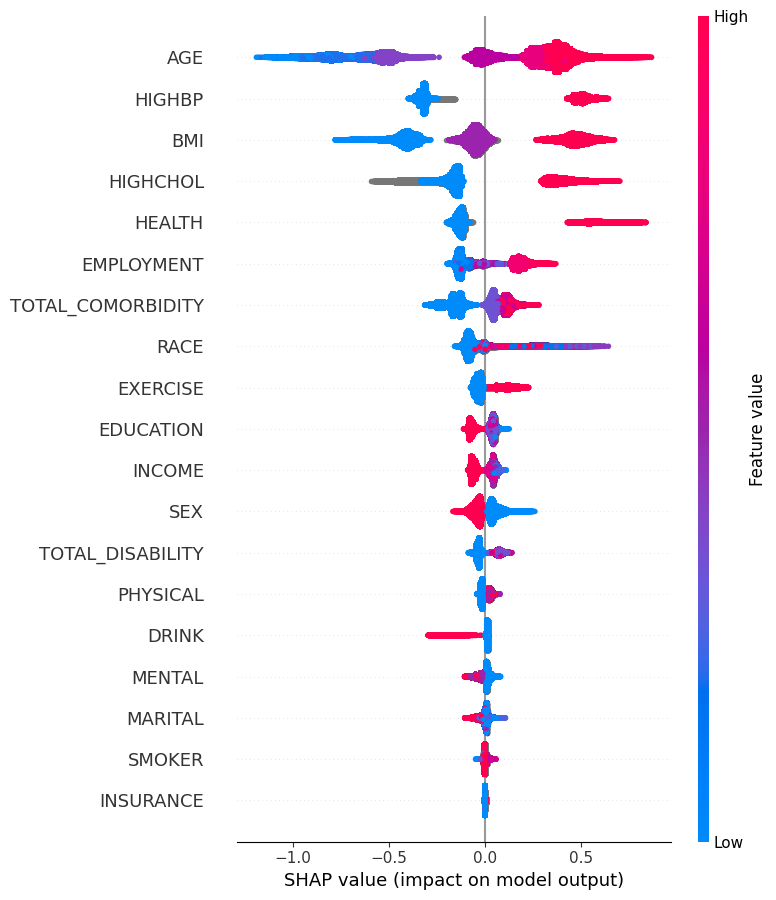

In [27]:
shap.summary_plot(explanation1)

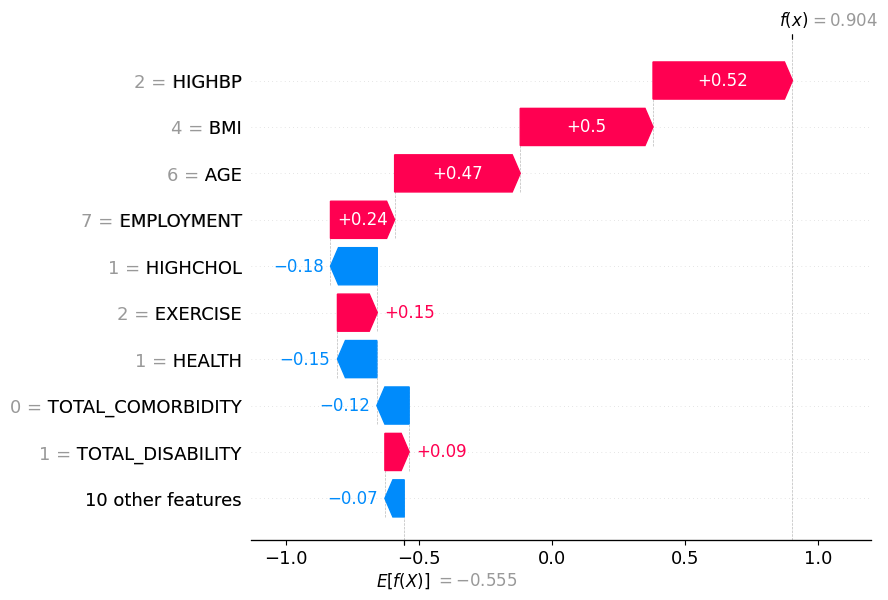

In [28]:
shap.plots.waterfall(explanation1[0])